In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('movie_dataset_encoded.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Saving movie_dataset_encoded.csv to movie_dataset_encoded (1).csv
Dataset loaded successfully!
Dataset shape: (5043, 154)


,director_name,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,actor_1_name,movie_title,...,country_Sweden,country_Switzerland,country_Taiwan,country_Thailand,country_Turkey,country_UK,country_USA,country_United Arab Emirates,country_West Germany,color_Color
0,James Cameron,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,CCH Pounder,Avatar,...,0,0,0,0,0,0,1,0,0,1
1,Gore Verbinski,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,Johnny Depp,Pirates of the Caribbean: At World's End,...,0,0,0,0,0,0,1,0,0,1
2,Sam Mendes,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,Christoph Waltz,Spectre,...,0,0,0,0,0,1,0,0,0,1
3,Christopher Nolan,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,Tom Hardy,The Dark Knight Rises,...,0,0,0,0,0,0,1,0,0,1
4,Doug Walker,103.0,131.0,371.5,Rob Walker,131.0,NaN,Documentary,Doug Walker,Star Wars: Episode VII - The Force Awakens ...,...,0,0,0,0,0,0,1,0,0,1


In [3]:
# Remove rows with missing target values
df = df.dropna(subset=['gross'])

# Columns that could cause data leakage
leakage_columns = [
    'imdb_score',
    'num_voted_users',
    'num_user_for_reviews',
    'num_critic_for_reviews',
    'movie_facebook_likes',
    'movie_age',
    'cast_popularity'
]

# Remove leakage columns if they exist
df = df.drop(
    columns=[col for col in leakage_columns if col in df.columns]
)

print("Dataset shape after preparation:", df.shape)

Dataset shape after preparation: (4159, 151)


In [4]:
# Select numerical columns
X = df.select_dtypes(include=['number']).drop(
    columns=['gross'], errors='ignore'
)

# Target variable
y = df['gross']

# Remove columns containing only missing values
X = X.dropna(axis=1, how='all')

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (4159, 143)
Target shape: (4159,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3327, 143)
Testing data: (832, 143)


In [6]:
imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns
)

print("Missing values handled successfully!")

Missing values handled successfully!


In [7]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [8]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                          Feature  Importance
6                          budget    0.410807
0                        duration    0.086665
8          actor_2_facebook_likes    0.073782
2          actor_3_facebook_likes    0.071475
7                      title_year    0.065520
..                            ...         ...
127              country_Slovakia    0.000000
134           country_Switzerland    0.000000
131          country_Soviet Union    0.000000
137                country_Turkey    0.000000
140  country_United Arab Emirates    0.000000

[143 rows x 2 columns]


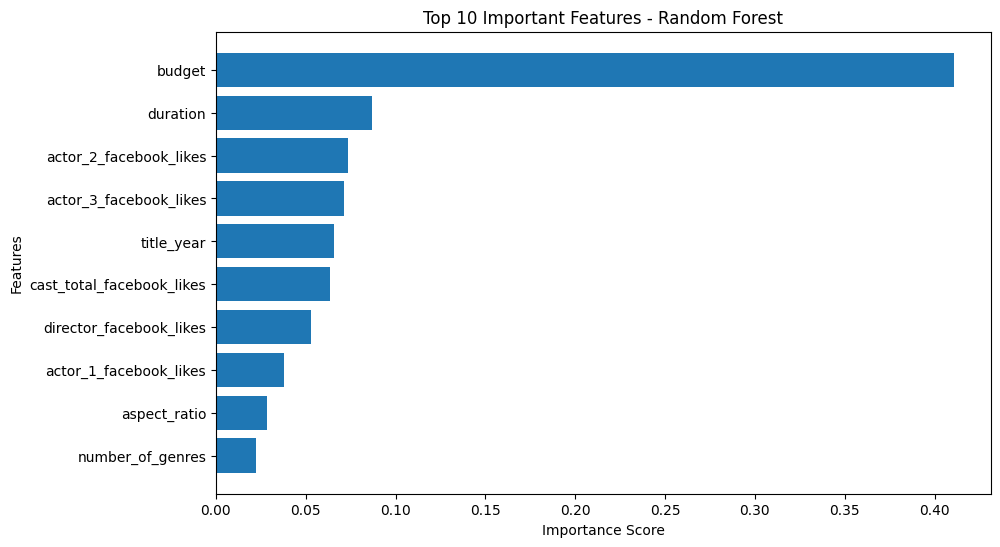

In [9]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Top 10 Important Features - Random Forest')
plt.gca().invert_yaxis()

plt.show()

In [10]:
selected_features = feature_importance.head(10)['Feature'].tolist()

print("Selected Features:")
for feature in selected_features:
    print(feature)

# Create dataset with selected features and target
selected_df = df[selected_features + ['gross']]

print("\nSelected dataset shape:", selected_df.shape)

selected_df.head()

Selected Features:
budget
duration
actor_2_facebook_likes
actor_3_facebook_likes
title_year
cast_total_facebook_likes
director_facebook_likes
actor_1_facebook_likes
aspect_ratio
number_of_genres

Selected dataset shape: (4159, 11)


,budget,duration,actor_2_facebook_likes,actor_3_facebook_likes,title_year,cast_total_facebook_likes,director_facebook_likes,actor_1_facebook_likes,aspect_ratio,number_of_genres,gross
0,237000000.0,178.0,936.0,855.0,2009.0,4834,0.0,1000.0,1.78,4,760505847.0
1,300000000.0,169.0,5000.0,1000.0,2007.0,48350,563.0,40000.0,2.35,3,309404152.0
2,245000000.0,148.0,393.0,161.0,2015.0,11700,0.0,11000.0,2.35,3,200074175.0
3,250000000.0,164.0,23000.0,23000.0,2012.0,106759,22000.0,27000.0,2.35,2,448130642.0
5,263700000.0,132.0,632.0,530.0,2012.0,1873,475.0,640.0,2.35,3,73058679.0


In [11]:
selected_df.to_csv(
    'movie_dataset_selected_features.csv',
    index=False
)

files.download('movie_dataset_selected_features.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>